<a href="https://colab.research.google.com/github/chulsoo3060/YOLO_SEJONG/blob/main/YOLO_custom_bottle_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!pip install -q ultralytics

from google.colab import files
import os

print("my-bottle-detection.v1i.yolov11.zip 파일을 선택하세요.")
uploaded = files.upload()

my-bottle-detection.v1i.yolov11.zip 파일을 선택하세요.


Saving my-bottle-detection.v1i.yolov11.zip to my-bottle-detection.v1i.yolov11 (1).zip


In [23]:
import os
import shutil

zip_path = "/content/my-bottle-detection.v1i.yolov11.zip"
dataset_dir = "/content/my_bottle_dataset"

# 기존 데이터셋 폴더가 있으면 삭제 후 다시 압축 해제
if os.path.exists(dataset_dir):
    shutil.rmtree(dataset_dir)

if os.path.exists(zip_path):
    !unzip -o -q "{zip_path}" -d "{dataset_dir}"
    print("압축 해제 완료")
else:
    print("ZIP 파일을 찾을 수 없습니다.")

압축 해제 완료


In [24]:
!ls /content/my_bottle_dataset

data.yaml  README.roboflow.txt	test  train  valid


In [25]:
from ultralytics import YOLO
import os
import shutil

RUN_DIR = "/content/runs/detect/my_bottle_yolo11"

# 이전 동일 실험 결과 제거
if os.path.exists(RUN_DIR):
    shutil.rmtree(RUN_DIR)

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/my_bottle_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,

    project="/content/runs/detect",
    name="my_bottle_yolo11",
    exist_ok=True
)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my_bottle_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=my_bottle_yolo11, nbs=64, nms=None, opset=None, optim

In [26]:
!ls /content/runs/detect/my_bottle_yolo11

args.yaml			 labels.jpg	     train_batch361.jpg
BoxF1_curve.png			 results.csv	     train_batch362.jpg
BoxP_curve.png			 results.png	     val_batch0_labels.jpg
BoxPR_curve.png			 train_batch0.jpg    val_batch0_pred.jpg
BoxR_curve.png			 train_batch1.jpg    val_batch1_labels.jpg
confusion_matrix_normalized.png  train_batch2.jpg    val_batch1_pred.jpg
confusion_matrix.png		 train_batch360.jpg  weights


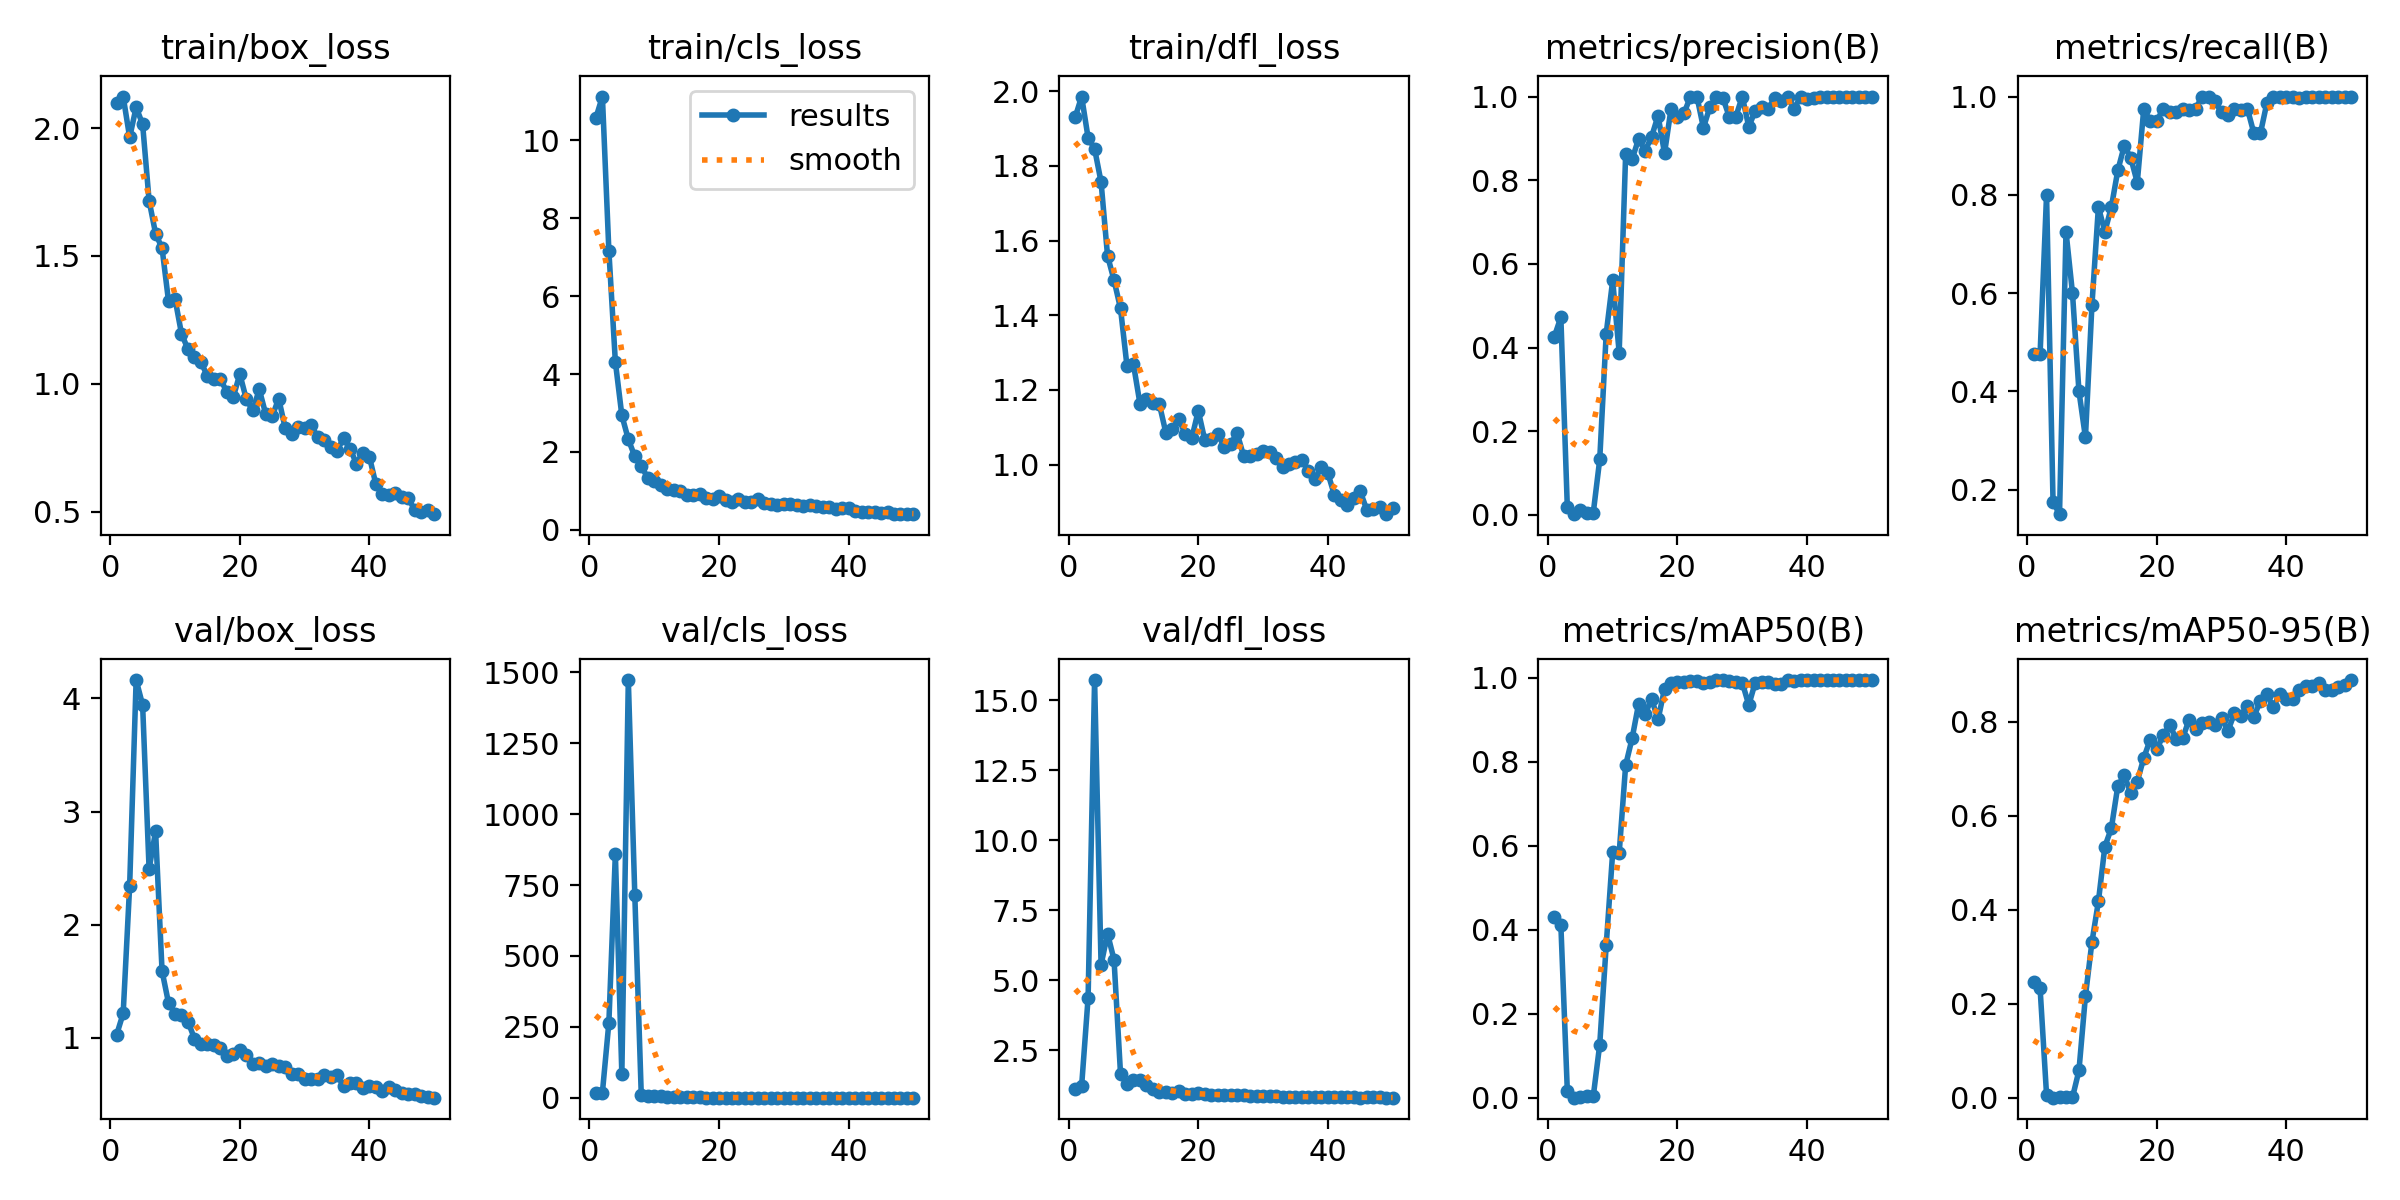

In [27]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/runs/detect/my_bottle_yolo11/results.png"
    )
)

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "/content/runs/detect/my_bottle_yolo11/results.csv"

df = pd.read_csv(csv_path)

df.columns = df.columns.str.strip()

print(df.columns)

Index(['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
       'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
       'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
       'lr/pg0', 'lr/pg1', 'lr/pg2'],
      dtype='object')


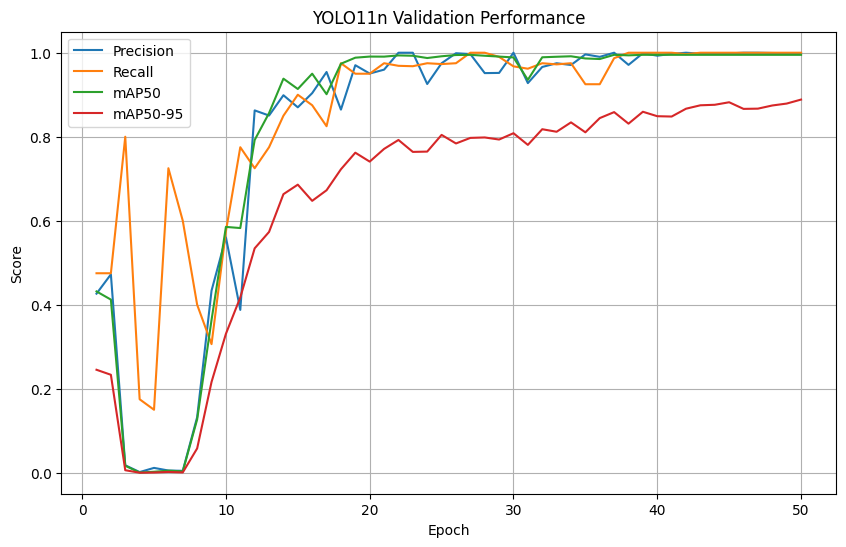

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df["metrics/precision(B)"], label="Precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="Recall")
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("YOLO11n Validation Performance")

plt.legend()
plt.grid()

plt.show()

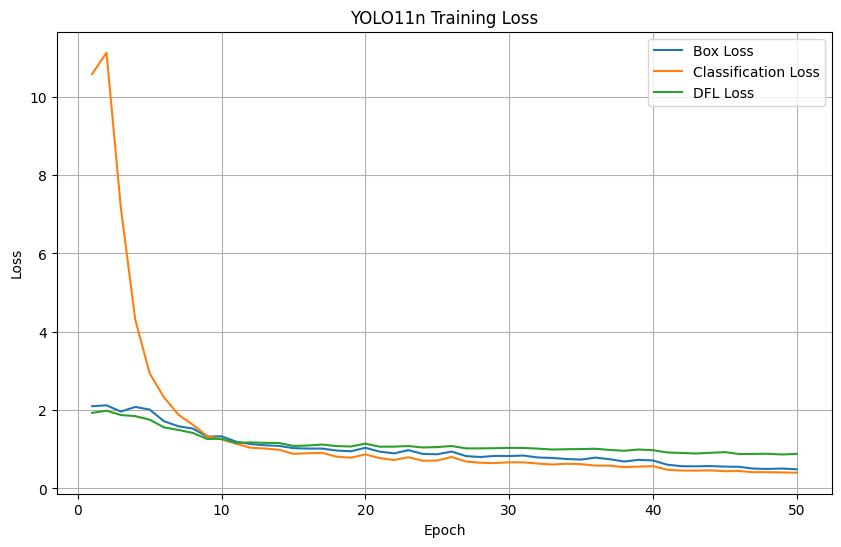

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/box_loss"],
    label="Box Loss"
)

plt.plot(
    df["epoch"],
    df["train/cls_loss"],
    label="Classification Loss"
)

plt.plot(
    df["epoch"],
    df["train/dfl_loss"],
    label="DFL Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO11n Training Loss")

plt.legend()
plt.grid()

plt.show()

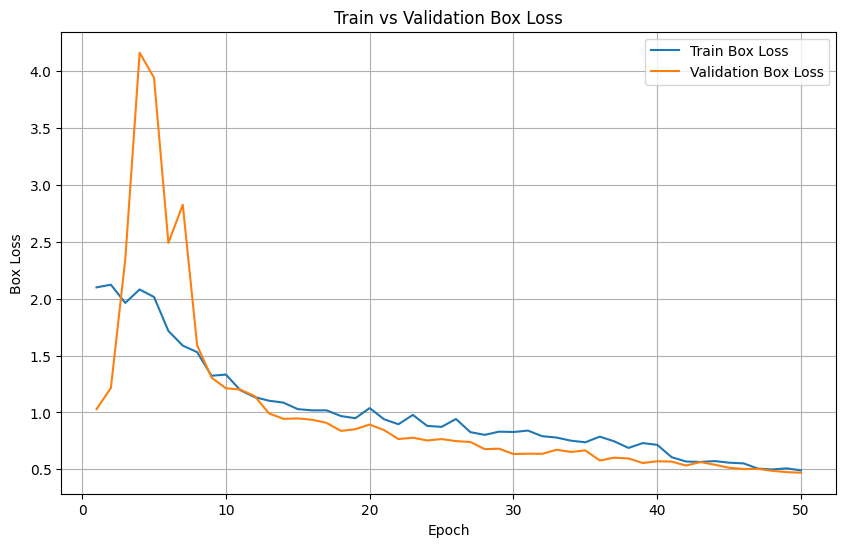

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/box_loss"],
    label="Train Box Loss"
)

plt.plot(
    df["epoch"],
    df["val/box_loss"],
    label="Validation Box Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Train vs Validation Box Loss")

plt.legend()
plt.grid()

plt.show()

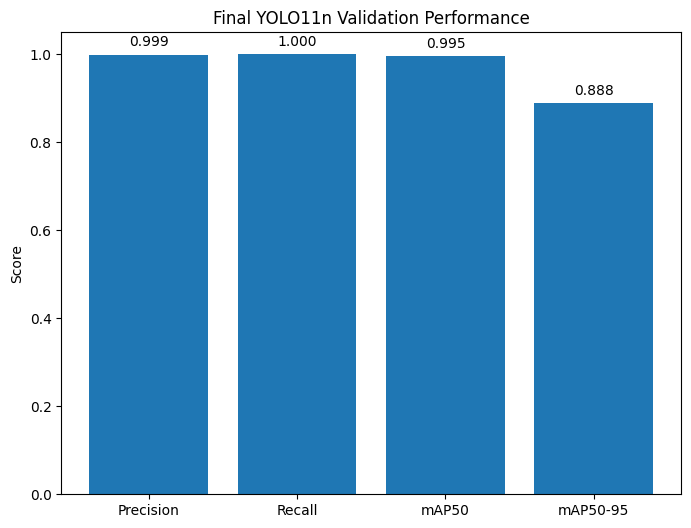

In [32]:
final_row = df.iloc[-1]

metrics_names = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

metrics_values = [
    final_row["metrics/precision(B)"],
    final_row["metrics/recall(B)"],
    final_row["metrics/mAP50(B)"],
    final_row["metrics/mAP50-95(B)"]
]

plt.figure(figsize=(8, 6))

plt.bar(
    metrics_names,
    metrics_values
)

plt.ylim(0, 1.05)

plt.ylabel("Score")
plt.title("Final YOLO11n Validation Performance")

for i, value in enumerate(metrics_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()